
# Simulasi Dampak Pola Tidur Tidak Teratur terhadap Produktivitas Mahasiswa
## Agent-Based Modeling dengan Mesa — Versi Revisi Final Notebook

Notebook ini menyajikan proses lengkap dari **pembuatan dataset dummy**, pemodelan agen, perhitungan perubahan produktivitas, penerapan intervensi, eksperimen *what-if*, 1.000 iterasi Monte Carlo, analisis hasil, sampai ekspor data untuk dashboard.

### Revisi utama
1. Library simulasi diubah dari SimPy menjadi **Mesa**, sesuai ketentuan tugas.
2. Dataset dummy dibuat dan ditampilkan secara eksplisit sebelum simulasi.
3. Skenario utama menggunakan kondisi awal yang sama agar perbandingan lebih adil.
4. Distorsi kognitif tinggi hanya mengubah parameter `D`.
5. Digunakan **seed yang sama pada iterasi yang sama** untuk menghasilkan *common random numbers*.
6. Formula matematika pada penjelasan disamakan dengan implementasi kode.
7. Ditambahkan state chart, metrik waktu dalam produktivitas rendah, interval kepercayaan, serta ekspor data untuk dashboard.
8. Skenario kombinasi ideal dipertahankan sebagai **benchmark eksploratif**, bukan sebagai pembanding kausal.

> **Batasan penggunaan:** model ini bersifat simulasi eksploratif dan bukan alat diagnosis klinis.



## 1. Tujuan dan Komponen Model

### Tujuan
Menganalisis perubahan tingkat produktivitas mahasiswa selama 16 minggu berdasarkan:

- jam tidur;
- kualitas tidur;
- keteraturan tidur;
- tekanan akademik;
- distorsi kognitif;
- intervensi higiene tidur.

### Komponen Agent-Based Modeling

| Komponen | Implementasi |
|---|---|
| Agen | Mahasiswa |
| Lingkungan | Semester selama 16 minggu |
| Stressor | Tekanan akademik dan lonjakan tekanan pada minggu ujian |
| Intervensi | Higiene tidur reaktif atau preventif |
| State | Produktivitas rendah, sedang, dan tinggi |
| Output | Produktivitas akhir, skor tidur, frekuensi intervensi, dan durasi produktivitas rendah |

### Pertanyaan eksperimen
1. Apa yang terjadi tanpa intervensi?
2. Seberapa efektif intervensi reaktif?
3. Apakah intervensi preventif lebih stabil?
4. Bagaimana pengaruh distorsi kognitif tinggi?
5. Seberapa tinggi hasil pada kondisi ideal sebagai benchmark?


## 2. Instalasi dan Import Library

In [1]:

# Instal Mesa hanya jika belum tersedia.
try:
    import mesa
except ImportError:
    %pip install -q "mesa>=3.0"
    import mesa

import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print(f"Mesa version : {mesa.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")


Note: you may need to restart the kernel to use updated packages.


d:\KULIAH S1\SEMESTER 6\penalaran komputer\SUB CPMK 3\cbr-putusan-ite-pn-surabaya\cbr-putusan-ite-pn-surabaya\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mesa version : 3.3.1
Pandas       : 3.0.3
NumPy        : 2.4.6



## 3. Dasar Literatur dan Asumsi Model

Literatur digunakan untuk mendukung **arah hubungan konseptual**, bukan untuk mengklaim bahwa seluruh bobot model telah terkalibrasi secara klinis.

- Rekomendasi untuk dewasa muda umumnya berada pada kisaran **7–9 jam tidur**. Nilai `7.5` jam pada model dipilih sebagai titik operasional di dalam rentang tersebut.
- Kajian sistematis pada mahasiswa menunjukkan bahwa durasi, kualitas, regularitas, dan gangguan tidur berkaitan dengan performa akademik, tetapi besar pengaruhnya bervariasi antarpenelitian.
- Bobot model, ambang produktivitas, besarnya lonjakan ujian, dan efek intervensi merupakan **asumsi simulasi** yang perlu dikalibrasi apabila tersedia data survei atau data empiris.

### Referensi
1. Watson, N. F., et al. (2015). *Recommended Amount of Sleep for a Healthy Adult: A Joint Consensus Recommendation of the American Academy of Sleep Medicine and Sleep Research Society*. Sleep, 38(6), 843–844. DOI: 10.5665/sleep.4716.
2. Hirshkowitz, M., et al. (2015). *National Sleep Foundation's sleep time duration recommendations: methodology and results summary*. Sleep Health, 1(1), 40–43. DOI: 10.1016/j.sleh.2014.12.010.
3. Suardiaz-Muro, M., et al. (2020). *Sleep and academic performance in university students: a systematic review*. Revista de Neurología, 71(2), 43–53. DOI: 10.33588/rn.7102.2020015.


## 4. Parameter Global dan Data Dictionary

In [2]:

# PARAMETER GLOBAL

SIM_TIME = 16
NUM_STUDENTS = 30
N_ITERASI = 1000
BASE_SEED = 2026

# Bobot komponen model
BOBOT_TIDUR = 0.28
BOBOT_KUALITAS = 0.22
BOBOT_REGULARITAS = 0.15
BOBOT_STRES = 0.25
BOBOT_INTERVENSI = 0.18
FAKTOR_PERUBAHAN = 0.22

# Nilai ideal dan ambang state
IDEAL_SLEEP = 7.5
INTERVENSI_THRESHOLD = 0.55
PRODUKTIVITAS_RENDAH = 0.40
PRODUKTIVITAS_TINGGI = 0.70

# Stressor lingkungan
EXAM_WEEKS = (7, 14)
EXAM_SPIKE = 0.15

parameter_global = pd.DataFrame({
    "Parameter": [
        "SIM_TIME", "NUM_STUDENTS", "N_ITERASI", "IDEAL_SLEEP",
        "INTERVENSI_THRESHOLD", "PRODUKTIVITAS_RENDAH",
        "PRODUKTIVITAS_TINGGI", "EXAM_WEEKS", "EXAM_SPIKE"
    ],
    "Nilai": [
        SIM_TIME, NUM_STUDENTS, N_ITERASI, IDEAL_SLEEP,
        INTERVENSI_THRESHOLD, PRODUKTIVITAS_RENDAH,
        PRODUKTIVITAS_TINGGI, str(EXAM_WEEKS), EXAM_SPIKE
    ],
    "Keterangan": [
        "Jumlah minggu semester",
        "Jumlah mahasiswa per simulasi",
        "Jumlah pengulangan per skenario",
        "Titik operasional jam tidur ideal",
        "Ambang aktivasi intervensi reaktif",
        "Batas bawah state sedang",
        "Batas bawah state tinggi",
        "Minggu dengan tekanan ujian",
        "Tambahan tekanan akademik saat ujian"
    ]
})

display(parameter_global)


,Parameter,Nilai,Keterangan
0,SIM_TIME,16,Jumlah minggu semester
1,NUM_STUDENTS,30,Jumlah mahasiswa per simulasi
2,N_ITERASI,1000,Jumlah pengulangan per skenario
3,IDEAL_SLEEP,7.5,Titik operasional jam tidur ideal
4,INTERVENSI_THRESHOLD,0.55,Ambang aktivasi intervensi reaktif
5,PRODUKTIVITAS_RENDAH,0.4,Batas bawah state sedang
6,PRODUKTIVITAS_TINGGI,0.7,Batas bawah state tinggi
7,EXAM_WEEKS,"(7, 14)",Minggu dengan tekanan ujian
8,EXAM_SPIKE,0.15,Tambahan tekanan akademik saat ujian



### Data dictionary agen

| Variabel | Nama lengkap | Rentang | Arti |
|---|---|---:|---|
| `PL` | Productivity Level | 0–1 | Tingkat produktivitas |
| `SH` | Sleep Hours | 3–10 | Jam tidur per malam |
| `SQ` | Sleep Quality | 0–1 | Kualitas tidur |
| `SR` | Sleep Regularity | 0–1 | Keteraturan tidur |
| `AS` | Academic Stress | 0–1 | Tekanan akademik dasar |
| `D` | Cognitive Distortion | ≥ 0 | Penguat dampak stressor tidur |
| `HI` | Hygiene Intervention | 0–1 | Kekuatan intervensi |

### Formula yang digunakan

\[
SleepScore_t =
1-\min\left(\frac{|SH_t-7.5|}{4.5},1\right)
\]

\[
StresTidur_t =
(1-SleepScore_t)(1-SR_t)
\]

\[
StresAkademik_t =
\min(1, AS + ExamSpike_t)
\]

\[
ManfaatTidur_t =
0.28(SleepScore_t)+0.22(SQ_t)+0.15(SR_t)
\]

\[
DampakStres_t =
0.25\left(StresAkademik_t+D \times StresTidur_t\right)
\]

\[
\Delta_t =
0.22(ManfaatTidur_t-DampakStres_t)
\]

Pembaruan produktivitas menggunakan fungsi pembatas:

\[
PL_{t+1} =
\begin{cases}
PL_t+\Delta_t(1-PL_t), & \Delta_t \ge 0 \\
PL_t+\Delta_tPL_t, & \Delta_t < 0
\end{cases}
\]

Nilai akhir selalu dibatasi pada interval `[0, 1]`.


## 5. Definisi Skenario yang Terkontrol

In [3]:

# Kondisi awal dasar digunakan bersama oleh tiga skenario utama.
BASELINE_PARAMS = {
    "PL_min": 0.40, "PL_max": 0.75,
    "SH_min": 4.00, "SH_max": 6.00,
    "SQ_min": 0.25, "SQ_max": 0.55,
    "SR_min": 0.15, "SR_max": 0.40,
    "AS_min": 0.60, "AS_max": 0.90,
    "D_min": 1.20, "D_max": 2.00,
    "HI_min": 0.65, "HI_max": 0.85,
}

def ubah_parameter(base, **perubahan):
    hasil = base.copy()
    hasil.update(perubahan)
    return hasil

skenario_all = {
    "Tanpa Intervensi": ubah_parameter(
        BASELINE_PARAMS,
        mode="none",
        kategori="Eksperimen utama"
    ),
    "Intervensi Reaktif": ubah_parameter(
        BASELINE_PARAMS,
        mode="reaktif",
        kategori="Eksperimen utama"
    ),
    "Intervensi Preventif": ubah_parameter(
        BASELINE_PARAMS,
        mode="preventif",
        kategori="Eksperimen utama"
    ),
    "Distorsi Kognitif Tinggi": ubah_parameter(
        BASELINE_PARAMS,
        mode="reaktif",
        D_min=2.00,
        D_max=3.00,
        kategori="Eksperimen utama"
    ),
    "Kombinasi Ideal (Benchmark)": ubah_parameter(
        BASELINE_PARAMS,
        mode="preventif",
        SH_min=7.00, SH_max=8.20,
        SQ_min=0.75, SQ_max=0.95,
        SR_min=0.75, SR_max=0.95,
        AS_min=0.25, AS_max=0.50,
        D_min=0.80, D_max=1.20,
        HI_min=0.80, HI_max=1.00,
        kategori="Benchmark eksploratif"
    ),
}

# Pemeriksaan desain eksperimen:
# Tiga skenario pertama hanya boleh berbeda pada mode intervensi.
parameter_kondisi_awal = [
    "PL_min", "PL_max", "SH_min", "SH_max", "SQ_min", "SQ_max",
    "SR_min", "SR_max", "AS_min", "AS_max", "D_min", "D_max",
    "HI_min", "HI_max"
]

for key in parameter_kondisi_awal:
    assert skenario_all["Tanpa Intervensi"][key] == skenario_all["Intervensi Reaktif"][key]
    assert skenario_all["Tanpa Intervensi"][key] == skenario_all["Intervensi Preventif"][key]

# Distorsi tinggi hanya mengubah D dibandingkan intervensi reaktif.
for key in parameter_kondisi_awal:
    if key not in ("D_min", "D_max"):
        assert skenario_all["Intervensi Reaktif"][key] == skenario_all["Distorsi Kognitif Tinggi"][key]

print("Validasi desain skenario berhasil.")


Validasi desain skenario berhasil.


In [4]:

# Tabel parameter skenario untuk presentasi dan dashboard
baris_skenario = []

for nama, p in skenario_all.items():
    baris_skenario.append({
        "Skenario": nama,
        "Kategori": p["kategori"],
        "Mode": p["mode"],
        "PL": f'{p["PL_min"]:.2f}–{p["PL_max"]:.2f}',
        "SH": f'{p["SH_min"]:.2f}–{p["SH_max"]:.2f}',
        "SQ": f'{p["SQ_min"]:.2f}–{p["SQ_max"]:.2f}',
        "SR": f'{p["SR_min"]:.2f}–{p["SR_max"]:.2f}',
        "AS": f'{p["AS_min"]:.2f}–{p["AS_max"]:.2f}',
        "D": f'{p["D_min"]:.2f}–{p["D_max"]:.2f}',
        "HI": f'{p["HI_min"]:.2f}–{p["HI_max"]:.2f}',
    })

df_parameter_skenario = pd.DataFrame(baris_skenario)
display(df_parameter_skenario)


,Skenario,Kategori,Mode,PL,SH,SQ,SR,AS,D,HI
0,Tanpa Intervensi,Eksperimen utama,none,0.40–0.75,4.00–6.00,0.25–0.55,0.15–0.40,0.60–0.90,1.20–2.00,0.65–0.85
1,Intervensi Reaktif,Eksperimen utama,reaktif,0.40–0.75,4.00–6.00,0.25–0.55,0.15–0.40,0.60–0.90,1.20–2.00,0.65–0.85
2,Intervensi Preventif,Eksperimen utama,preventif,0.40–0.75,4.00–6.00,0.25–0.55,0.15–0.40,0.60–0.90,1.20–2.00,0.65–0.85
3,Distorsi Kognitif Tinggi,Eksperimen utama,reaktif,0.40–0.75,4.00–6.00,0.25–0.55,0.15–0.40,0.60–0.90,2.00–3.00,0.65–0.85
4,Kombinasi Ideal (Benchmark),Benchmark eksploratif,preventif,0.40–0.75,7.00–8.20,0.75–0.95,0.75–0.95,0.25–0.50,0.80–1.20,0.80–1.00



## 6. Pembuatan Dataset Dummy

Dataset tidak diambil dari file eksternal. Data awal mahasiswa dibuat secara sintetis menggunakan distribusi uniform:

\[
X \sim U(X_{min},X_{max})
\]

Setiap mahasiswa memperoleh nilai awal yang berbeda. Fungsi menggunakan objek `random.Random(seed)` sehingga:

1. hasil dapat direproduksi;
2. setiap iterasi memiliki populasi yang berbeda;
3. skenario pada nomor iterasi yang sama menggunakan angka acak dasar yang sama;
4. perbedaan hasil lebih mudah dikaitkan dengan kebijakan skenario.

Dataset awal berisi satu baris per mahasiswa. Dataset longitudinal baru terbentuk setelah simulasi dijalankan selama 16 minggu.


In [5]:

def buat_dataset_dummy(params, n_mahasiswa=NUM_STUDENTS, seed=BASE_SEED):
    '''
    Membuat dataset awal mahasiswa dari rentang parameter skenario.

    Parameters
    ----------
    params : dict
        Parameter skenario.
    n_mahasiswa : int
        Jumlah mahasiswa.
    seed : int
        Seed lokal untuk reproduksibilitas.

    Returns
    -------
    pandas.DataFrame
        Dataset awal agen.
    '''
    rng = random.Random(seed)
    data = []

    for i in range(1, n_mahasiswa + 1):
        data.append({
            "Nama": f"Mhs-{i}",
            "PL_awal": rng.uniform(params["PL_min"], params["PL_max"]),
            "SH_awal": rng.uniform(params["SH_min"], params["SH_max"]),
            "SQ_awal": rng.uniform(params["SQ_min"], params["SQ_max"]),
            "SR_awal": rng.uniform(params["SR_min"], params["SR_max"]),
            "AS": rng.uniform(params["AS_min"], params["AS_max"]),
            "D": rng.uniform(params["D_min"], params["D_max"]),
            "HI": rng.uniform(params["HI_min"], params["HI_max"]),
        })

    return pd.DataFrame(data)

df_dummy_presentasi = buat_dataset_dummy(
    skenario_all["Tanpa Intervensi"],
    n_mahasiswa=NUM_STUDENTS,
    seed=BASE_SEED
)

print(f"Ukuran dataset awal: {df_dummy_presentasi.shape[0]} baris × {df_dummy_presentasi.shape[1]} kolom")
display(df_dummy_presentasi.head(10).round(4))
display(df_dummy_presentasi.describe().round(4))


Ukuran dataset awal: 30 baris × 8 kolom


,Nama,PL_awal,SH_awal,SQ_awal,SR_awal,AS,D,HI
0,Mhs-1,0.4417,5.0050,0.4035,0.3650,0.6308,1.3786,0.7702
1,Mhs-2,0.5948,5.5667,0.4143,0.3326,0.8304,1.8008,0.7673
2,Mhs-3,0.4840,5.2284,0.2832,0.3542,0.7349,1.8518,0.7870
3,Mhs-4,0.6378,4.4204,0.3255,0.3950,0.8788,1.8441,0.8499
4,Mhs-5,0.5798,4.1526,0.3521,0.2894,0.6876,1.5660,0.8253
5,Mhs-6,0.6464,5.1548,0.2574,0.3277,0.7091,1.5378,0.7298
6,Mhs-7,0.6050,4.9969,0.2849,0.2766,0.8250,1.6801,0.7482
7,Mhs-8,0.7209,4.5173,0.3760,0.3816,0.7438,1.6144,0.6551
8,Mhs-9,0.4786,4.2580,0.2647,0.3262,0.8660,1.2821,0.7745
9,Mhs-10,0.5645,4.9642,0.3187,0.3715,0.7880,1.5654,0.7439


,PL_awal,SH_awal,SQ_awal,SR_awal,AS,D,HI
count,30.0000,30.0000,30.0000,30.0000,30.0000,30.0000,30.0000
mean,0.5729,5.0264,0.3690,0.3018,0.7576,1.6295,0.7616
std,0.0941,0.5487,0.0854,0.0607,0.0820,0.2281,0.0568
min,0.4180,4.1526,0.2574,0.1823,0.6042,1.2002,0.6551
25%,0.5064,4.6611,0.2874,0.2642,0.7137,1.4674,0.7298
50%,0.5739,5.0010,0.3541,0.2948,0.7732,1.6102,0.7597
75%,0.6328,5.4362,0.4142,0.3513,0.8291,1.8400,0.8147
max,0.7378,5.9745,0.5153,0.3950,0.8788,1.9666,0.8499



## 7. State Chart Produktivitas

| State | Kondisi |
|---|---|
| Rendah | `PL < 0.40` |
| Sedang | `0.40 ≤ PL < 0.70` |
| Tinggi | `PL ≥ 0.70` |
| Pulih | State sebelumnya rendah dan state sekarang sedang/tinggi |

Alur transisi:

```text
Tinggi  ↔  Sedang  ↔  Rendah
                     │
                     └── intervensi berhasil ──> Pulih ke Sedang/Tinggi
```

State dihitung kembali pada setiap minggu. Model juga mencatat jumlah minggu yang dialami setiap mahasiswa pada state rendah.


## 8. Kelas Agen dan Model Mesa

In [6]:

class Mahasiswa(mesa.Agent):
    '''
    Agen mahasiswa dalam model pola tidur dan produktivitas.
    '''

    def __init__(self, model, row):
        super().__init__(model)

        self.nama = row.Nama
        self.mode = model.mode

        self.PL = float(row.PL_awal)
        self.SH = float(row.SH_awal)
        self.SQ = float(row.SQ_awal)
        self.SR = float(row.SR_awal)
        self.AS = float(row.AS)
        self.D = float(row.D)
        self.HI = float(row.HI)

        self.state_sebelumnya = self.tentukan_state()
        self.jumlah_intervensi = 0
        self.jumlah_minggu_rendah = 0
        self.sleep_score_terakhir = self.hitung_sleep_score()

    def tentukan_state(self):
        if self.PL >= PRODUKTIVITAS_TINGGI:
            return "Tinggi"
        if self.PL >= PRODUKTIVITAS_RENDAH:
            return "Sedang"
        return "Rendah"

    def hitung_sleep_score(self):
        deviasi = abs(self.SH - IDEAL_SLEEP)
        score = 1 - min(deviasi / 4.5, 1)
        return max(0.0, min(score, 1.0))

    def fluktuasi_tidur(self):
        # Semakin rendah regularitas, semakin besar perubahan jam tidur.
        perubahan_jam = self.random.uniform(-0.35, 0.35) * (1 - self.SR)
        perubahan_kualitas = self.random.uniform(-0.04, 0.03)

        self.SH = max(3.0, min(self.SH + perubahan_jam, 10.0))
        self.SQ = max(0.10, min(self.SQ + perubahan_kualitas, 1.0))

    def hitung_stressor(self):
        exam_spike = EXAM_SPIKE if self.model.minggu in EXAM_WEEKS else 0.0
        stres_akademik = min(1.0, self.AS + exam_spike)

        sleep_score = self.hitung_sleep_score()
        stres_tidur = (1 - sleep_score) * (1 - self.SR)

        return stres_akademik, stres_tidur, sleep_score

    def intervensi_diperlukan(self):
        if self.mode == "preventif":
            return True
        if self.mode == "reaktif" and self.PL < INTERVENSI_THRESHOLD:
            return True
        return False

    def step(self):
        # 1. Kondisi tidur berubah secara stokastik.
        self.fluktuasi_tidur()

        # 2. Stressor lingkungan dan tidur dihitung.
        stres_akademik, stres_tidur, sleep_score_sebelum = self.hitung_stressor()

        # 3. Komponen manfaat dan beban dihitung.
        manfaat_tidur = (
            BOBOT_TIDUR * sleep_score_sebelum
            + BOBOT_KUALITAS * self.SQ
            + BOBOT_REGULARITAS * self.SR
        )

        dampak_stres = BOBOT_STRES * (
            stres_akademik + self.D * stres_tidur
        )

        delta = FAKTOR_PERUBAHAN * (manfaat_tidur - dampak_stres)

        # 4. Produktivitas diperbarui dengan fungsi pembatas.
        if delta >= 0:
            self.PL += delta * (1 - self.PL)
        else:
            self.PL += delta * self.PL

        # 5. Kebijakan intervensi diterapkan.
        intervensi_aktif = self.intervensi_diperlukan()

        if intervensi_aktif and self.HI > 0:
            self.jumlah_intervensi += 1
            efek_intervensi = BOBOT_INTERVENSI * self.HI

            self.PL += 0.08 * efek_intervensi * (1 - self.PL)
            self.SH += (IDEAL_SLEEP - self.SH) * 0.10 * self.HI
            self.SQ = min(1.0, self.SQ + 0.025 * self.HI)
            self.SR = min(1.0, self.SR + 0.030 * self.HI)

        self.PL = max(0.0, min(self.PL, 1.0))

        # SleepScore dihitung ulang setelah intervensi agar konsisten
        # dengan SH, SQ, dan SR yang dicatat pada akhir minggu.
        self.sleep_score_terakhir = self.hitung_sleep_score()

        state_sekarang = self.tentukan_state()
        pulih = self.state_sebelumnya == "Rendah" and state_sekarang != "Rendah"

        if state_sekarang == "Rendah":
            self.jumlah_minggu_rendah += 1

        if self.model.collect_history:
            transisi = (
                f"{self.state_sebelumnya} → {state_sekarang}"
                if self.state_sebelumnya != state_sekarang
                else state_sekarang
            )

            self.model.records.append({
                "Nama": self.nama,
                "Minggu": self.model.minggu,
                "PL": self.PL,
                "SH": self.SH,
                "SQ": self.SQ,
                "SR": self.SR,
                "AS": self.AS,
                "D": self.D,
                "HI": self.HI,
                "SleepScore": self.sleep_score_terakhir,
                "StresAkademik": stres_akademik,
                "StresTidur": stres_tidur,
                "Intervensi": intervensi_aktif,
                "Produktivitas": state_sekarang,
                "Transisi": transisi,
                "Pulih": pulih,
            })

        self.state_sebelumnya = state_sekarang


class ModelTidurProduktivitas(mesa.Model):
    '''
    Lingkungan simulasi untuk semester selama SIM_TIME minggu.
    '''

    def __init__(
        self,
        initial_data,
        mode,
        seed=BASE_SEED,
        sim_time=SIM_TIME,
        collect_history=False,
    ):
        super().__init__(rng=seed)

        self.mode = mode
        self.sim_time = sim_time
        self.collect_history = collect_history
        self.minggu = 0
        self.records = []

        for row in initial_data.itertuples(index=False):
            Mahasiswa(self, row)

    def step(self):
        self.minggu += 1
        # Urutan aktivasi agen diacak setiap minggu oleh Mesa.
        self.agents.shuffle_do("step")

    def run_model(self):
        for _ in range(self.sim_time):
            self.step()

        return pd.DataFrame(self.records)



### Proses satu minggu simulasi

```text
1. Jam dan kualitas tidur berfluktuasi
2. SleepScore dihitung
3. Stressor akademik dan tidur dihitung
4. Manfaat tidur dan dampak stressor dihitung
5. Productivity Level diperbarui
6. Sistem mengecek mode intervensi
7. Intervensi memperbaiki PL, SH, SQ, dan SR
8. SleepScore akhir dihitung ulang
9. State dan transisi disimpan
```

Minggu ke-7 dan ke-14 mendapat tambahan stressor ujian.


## 9. Demo Purwarupa: Lima Agen Tanpa Intervensi

Dataset awal demo:


,Nama,PL_awal,SH_awal,SQ_awal,SR_awal,AS,D,HI
0,Mhs-1,0.6238,4.0500,0.3325,0.2058,0.8209,1.7414,0.8284
1,Mhs-2,0.4304,4.8438,0.2589,0.2047,0.7516,1.2212,0.6898
2,Mhs-3,0.6275,5.0899,0.3161,0.2973,0.8428,1.2052,0.8112
3,Mhs-4,0.6443,4.6805,0.2966,0.3893,0.7010,1.2742,0.6693
4,Mhs-5,0.6966,5.2075,0.4921,0.3324,0.7609,1.9785,0.7257


Contoh dataset longitudinal:


,Nama,Minggu,PL,SH,SQ,SR,AS,D,HI,SleepScore,StresAkademik,StresTidur,Intervensi,Produktivitas,Transisi,Pulih
0,Mhs-4,1,0.6320,4.5714,0.2664,0.3893,0.7010,1.2742,0.6693,0.3492,0.7010,0.3974,False,Sedang,Sedang,False
1,Mhs-2,1,0.4160,4.6225,0.2708,0.2047,0.7516,1.2212,0.6898,0.3606,0.7516,0.5086,False,Sedang,Sedang,False
2,Mhs-3,1,0.6168,5.1122,0.3175,0.2973,0.8428,1.2052,0.8112,0.4694,0.8428,0.3729,False,Sedang,Sedang,False
3,Mhs-5,1,0.6813,4.9887,0.4587,0.3324,0.7609,1.9785,0.7257,0.4419,0.7609,0.3726,False,Sedang,Sedang,False
4,Mhs-1,1,0.5797,3.9014,0.3347,0.2058,0.8209,1.7414,0.8284,0.2003,0.8209,0.6351,False,Sedang,Sedang,False
5,Mhs-1,2,0.5360,3.7460,0.3359,0.2058,0.8209,1.7414,0.8284,0.1658,0.8209,0.6625,False,Sedang,Sedang,False
6,Mhs-4,2,0.6206,4.7037,0.2269,0.3893,0.7010,1.2742,0.6693,0.3786,0.7010,0.3795,False,Sedang,Sedang,False
7,Mhs-3,2,0.6088,5.2626,0.3263,0.2973,0.8428,1.2052,0.8112,0.5028,0.8428,0.3494,False,Sedang,Sedang,False
8,Mhs-2,2,0.4006,4.5336,0.2417,0.2047,0.7516,1.2212,0.6898,0.3408,0.7516,0.5243,False,Sedang,Sedang,False
9,Mhs-5,2,0.6701,5.2023,0.4423,0.3324,0.7609,1.9785,0.7257,0.4894,0.7609,0.3409,False,Sedang,Sedang,False


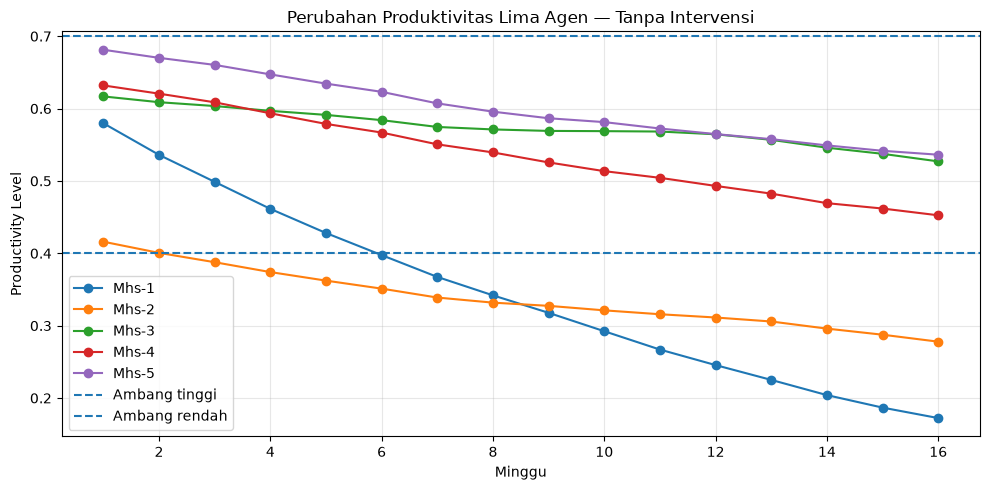

Snapshot minggu ke-16:


,Nama,PL,SH,SQ,SR,SleepScore,Produktivitas
75,Mhs-2,0.2779,4.6551,0.2524,0.2047,0.3678,Rendah
76,Mhs-3,0.5270,5.1899,0.2279,0.2973,0.4866,Sedang
77,Mhs-4,0.4525,4.8726,0.1000,0.3893,0.4161,Sedang
78,Mhs-1,0.1723,3.9599,0.1573,0.2058,0.2133,Rendah
79,Mhs-5,0.5362,5.5669,0.3499,0.3324,0.5704,Sedang


In [7]:

params_demo = skenario_all["Tanpa Intervensi"]

df_demo_awal = buat_dataset_dummy(
    params_demo,
    n_mahasiswa=5,
    seed=42
)

model_demo = ModelTidurProduktivitas(
    initial_data=df_demo_awal,
    mode=params_demo["mode"],
    seed=42,
    collect_history=True
)

df_demo = model_demo.run_model()

print("Dataset awal demo:")
display(df_demo_awal.round(4))

print("Contoh dataset longitudinal:")
display(df_demo.head(10).round(4))

plt.figure(figsize=(10, 5))
for nama, subset in df_demo.groupby("Nama"):
    plt.plot(subset["Minggu"], subset["PL"], marker="o", label=nama)

plt.axhline(PRODUKTIVITAS_TINGGI, linestyle="--", label="Ambang tinggi")
plt.axhline(PRODUKTIVITAS_RENDAH, linestyle="--", label="Ambang rendah")
plt.xlabel("Minggu")
plt.ylabel("Productivity Level")
plt.title("Perubahan Produktivitas Lima Agen — Tanpa Intervensi")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_demo_lima_agen.png", dpi=150, bbox_inches="tight")
plt.show()

print("Snapshot minggu ke-16:")
display(
    df_demo[df_demo["Minggu"] == SIM_TIME][
        ["Nama", "PL", "SH", "SQ", "SR", "SleepScore", "Produktivitas"]
    ].round(4)
)


## 10. Fungsi Satu Kali Simulasi

In [8]:

def run_simulation(
    skenario_params,
    seed,
    n_mahasiswa=NUM_STUDENTS,
    return_history=False,
):
    '''
    Menjalankan satu simulasi untuk satu skenario.

    Dataset awal dibuat terlebih dahulu, kemudian diberikan kepada model Mesa.
    '''
    initial_data = buat_dataset_dummy(
        skenario_params,
        n_mahasiswa=n_mahasiswa,
        seed=seed
    )

    model = ModelTidurProduktivitas(
        initial_data=initial_data,
        mode=skenario_params["mode"],
        seed=seed,
        collect_history=return_history
    )

    history = model.run_model()
    agents = list(model.agents)

    metrics = {
        "Avg_PL": np.mean([agent.PL for agent in agents]),
        "Pct_Rendah": np.mean([
            agent.PL < PRODUKTIVITAS_RENDAH for agent in agents
        ]) * 100,
        "Pct_Tinggi": np.mean([
            agent.PL >= PRODUKTIVITAS_TINGGI for agent in agents
        ]) * 100,
        "Avg_Intervensi": np.mean([
            agent.jumlah_intervensi for agent in agents
        ]),
        "Avg_SleepScore": np.mean([
            agent.sleep_score_terakhir for agent in agents
        ]),
        "Avg_Minggu_Rendah": np.mean([
            agent.jumlah_minggu_rendah for agent in agents
        ]),
    }

    if return_history:
        return metrics, initial_data, history

    return metrics


# Uji fungsi satu kali
contoh_metrics = run_simulation(
    skenario_all["Intervensi Reaktif"],
    seed=BASE_SEED
)

pd.Series(contoh_metrics, name="Nilai").round(4).to_frame()


,Nilai
Avg_PL,0.6046
Pct_Rendah,0.0000
Pct_Tinggi,3.3333
Avg_Intervensi,6.5667
Avg_SleepScore,0.6611
Avg_Minggu_Rendah,0.0000



## 11. Eksperimen Monte Carlo

Setiap skenario dijalankan sebanyak 1.000 kali.

\[
5\ skenario \times 1000\ iterasi \times 30\ mahasiswa \times 16\ minggu
= 2.400.000\ pembaruan\ agen\text{-}minggu
\]

Pada iterasi ke-\(i\), seluruh skenario menggunakan seed:

\[
seed_i = BASE\_SEED + i
\]

Teknik ini disebut **common random numbers**. Tiga skenario utama memperoleh populasi awal dan gangguan stokastik yang sebanding, sehingga perbandingan kebijakan menjadi lebih terkontrol.


In [9]:

iteration_results = []

for nama_skenario, params in skenario_all.items():
    print(f"Menjalankan: {nama_skenario}")

    for i in range(N_ITERASI):
        seed_iterasi = BASE_SEED + i
        metrics = run_simulation(
            params,
            seed=seed_iterasi,
            n_mahasiswa=NUM_STUDENTS
        )

        iteration_results.append({
            "Skenario": nama_skenario,
            "Kategori": params["kategori"],
            "Iterasi": i + 1,
            "Seed": seed_iterasi,
            **metrics,
        })

df_iterasi = pd.DataFrame(iteration_results)

print(f"Monte Carlo selesai: {len(df_iterasi):,} baris hasil iterasi.")
display(df_iterasi.head().round(4))


Menjalankan: Tanpa Intervensi
Menjalankan: Intervensi Reaktif
Menjalankan: Intervensi Preventif
Menjalankan: Distorsi Kognitif Tinggi
Menjalankan: Kombinasi Ideal (Benchmark)
Monte Carlo selesai: 5,000 baris hasil iterasi.


,Skenario,Kategori,Iterasi,Seed,Avg_PL,Pct_Rendah,Pct_Tinggi,Avg_Intervensi,Avg_SleepScore,Avg_Minggu_Rendah
0,Tanpa Intervensi,Eksperimen utama,1,2026,0.3932,50.0000,3.3333,0.0,0.4255,3.7667
1,Tanpa Intervensi,Eksperimen utama,2,2027,0.3755,60.0000,0.0000,0.0,0.4270,5.3667
2,Tanpa Intervensi,Eksperimen utama,3,2028,0.4071,60.0000,3.3333,0.0,0.4413,4.3667
3,Tanpa Intervensi,Eksperimen utama,4,2029,0.3977,56.6667,0.0000,0.0,0.4498,3.9000
4,Tanpa Intervensi,Eksperimen utama,5,2030,0.4146,43.3333,3.3333,0.0,0.4520,4.2333


In [10]:

# Ringkasan per skenario
df_results = (
    df_iterasi
    .groupby(["Skenario", "Kategori"], as_index=False)
    .agg(
        Avg_PL=("Avg_PL", "mean"),
        Std_PL=("Avg_PL", "std"),
        Pct_Produktivitas_Rendah=("Pct_Rendah", "mean"),
        Pct_Produktivitas_Tinggi=("Pct_Tinggi", "mean"),
        Avg_Intervensi=("Avg_Intervensi", "mean"),
        Avg_SleepScore=("Avg_SleepScore", "mean"),
        Avg_Minggu_Rendah=("Avg_Minggu_Rendah", "mean"),
    )
)

df_results["SE_PL"] = df_results["Std_PL"] / np.sqrt(N_ITERASI)
df_results["CI95_PL"] = 1.96 * df_results["SE_PL"]
df_results["CI95_Bawah"] = df_results["Avg_PL"] - df_results["CI95_PL"]
df_results["CI95_Atas"] = df_results["Avg_PL"] + df_results["CI95_PL"]

urutan = list(skenario_all.keys())
df_results["Skenario"] = pd.Categorical(
    df_results["Skenario"],
    categories=urutan,
    ordered=True
)
df_results = df_results.sort_values("Skenario").reset_index(drop=True)

display(df_results.round(4))


,Skenario,Kategori,Avg_PL,Std_PL,Pct_Produktivitas_Rendah,Pct_Produktivitas_Tinggi,Avg_Intervensi,Avg_SleepScore,Avg_Minggu_Rendah,SE_PL,CI95_PL,CI95_Bawah,CI95_Atas
0,Tanpa Intervensi,Eksperimen utama,0.4073,0.0280,53.0200,3.9267,0.0000,0.4451,4.5001,0.0009,0.0017,0.4056,0.4090
1,Intervensi Reaktif,Eksperimen utama,0.6024,0.0100,0.0300,5.2667,6.6559,0.6725,0.1704,0.0003,0.0006,0.6018,0.6030
2,Intervensi Preventif,Eksperimen utama,0.7340,0.0155,0.0267,67.8467,16.0000,0.8396,0.1688,0.0005,0.0010,0.7331,0.7350
3,Distorsi Kognitif Tinggi,Eksperimen utama,0.5798,0.0104,0.6633,1.9267,9.4082,0.7382,0.7992,0.0003,0.0006,0.5792,0.5805
4,Kombinasi Ideal (Benchmark),Benchmark eksploratif,0.9507,0.0022,0.0000,100.0000,16.0000,0.9846,0.0000,0.0001,0.0001,0.9505,0.9508


## 12. Visualisasi Hasil

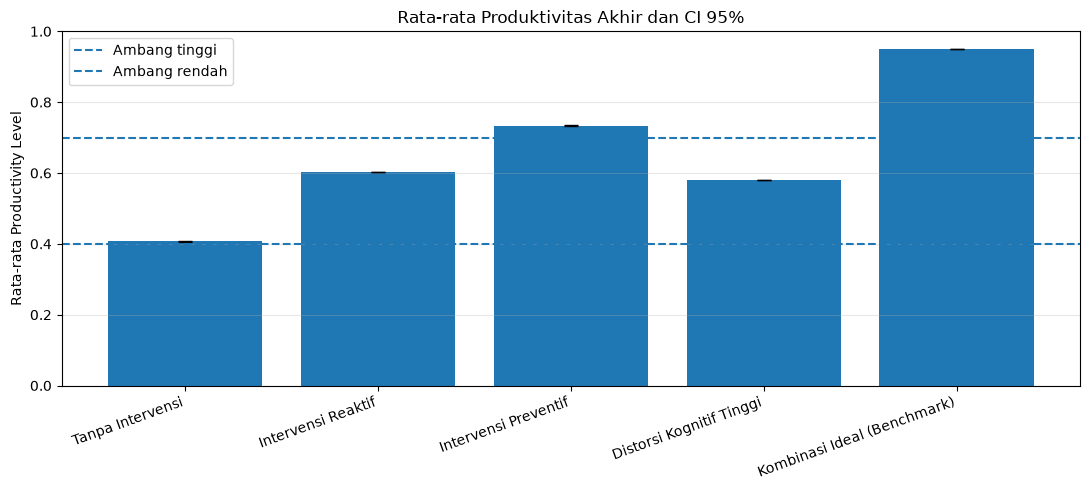

In [11]:

# Grafik 1 — Rata-rata PL dan interval kepercayaan 95%
plt.figure(figsize=(11, 5))
plt.bar(
    df_results["Skenario"].astype(str),
    df_results["Avg_PL"],
    yerr=df_results["CI95_PL"],
    capsize=5
)
plt.axhline(PRODUKTIVITAS_TINGGI, linestyle="--", label="Ambang tinggi")
plt.axhline(PRODUKTIVITAS_RENDAH, linestyle="--", label="Ambang rendah")
plt.ylim(0, 1)
plt.ylabel("Rata-rata Productivity Level")
plt.title("Rata-rata Produktivitas Akhir dan CI 95%")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_rata_rata_pl_ci95.png", dpi=150, bbox_inches="tight")
plt.show()


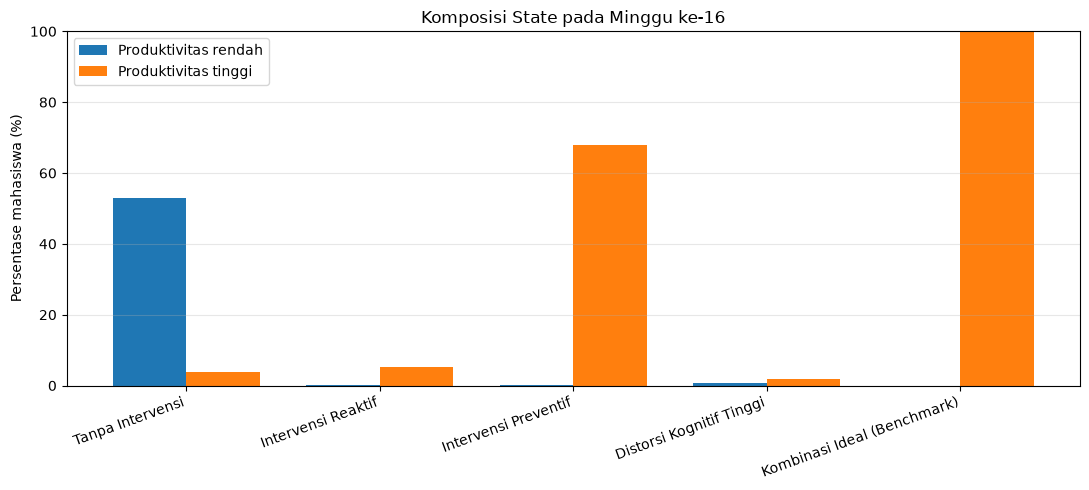

In [12]:

# Grafik 2 — Persentase state rendah dan tinggi
x = np.arange(len(df_results))
width = 0.38

plt.figure(figsize=(11, 5))
plt.bar(
    x - width / 2,
    df_results["Pct_Produktivitas_Rendah"],
    width,
    label="Produktivitas rendah"
)
plt.bar(
    x + width / 2,
    df_results["Pct_Produktivitas_Tinggi"],
    width,
    label="Produktivitas tinggi"
)
plt.ylabel("Persentase mahasiswa (%)")
plt.title("Komposisi State pada Minggu ke-16")
plt.xticks(x, df_results["Skenario"].astype(str), rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_state_akhir.png", dpi=150, bbox_inches="tight")
plt.show()


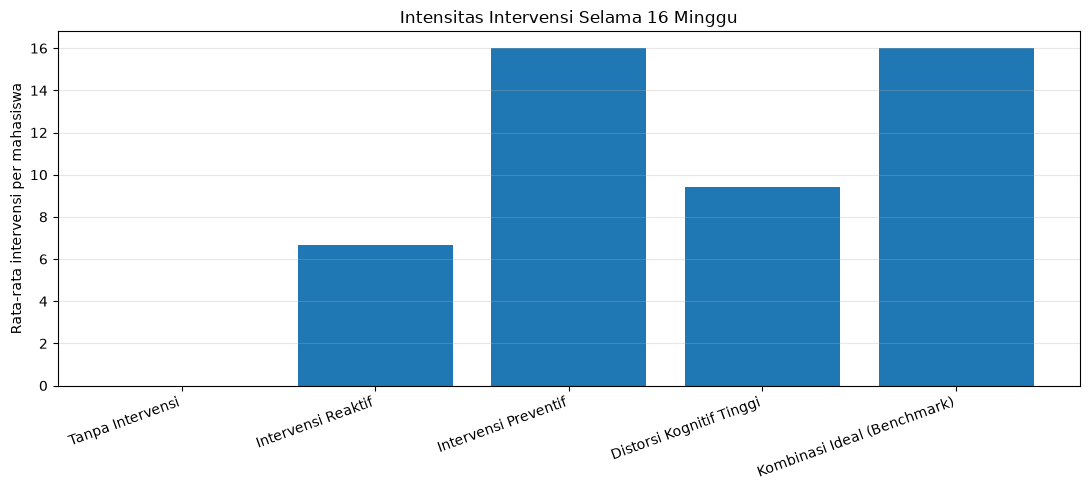

In [13]:

# Grafik 3 — Frekuensi intervensi
plt.figure(figsize=(11, 5))
plt.bar(
    df_results["Skenario"].astype(str),
    df_results["Avg_Intervensi"]
)
plt.ylabel("Rata-rata intervensi per mahasiswa")
plt.title("Intensitas Intervensi Selama 16 Minggu")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_frekuensi_intervensi.png", dpi=150, bbox_inches="tight")
plt.show()


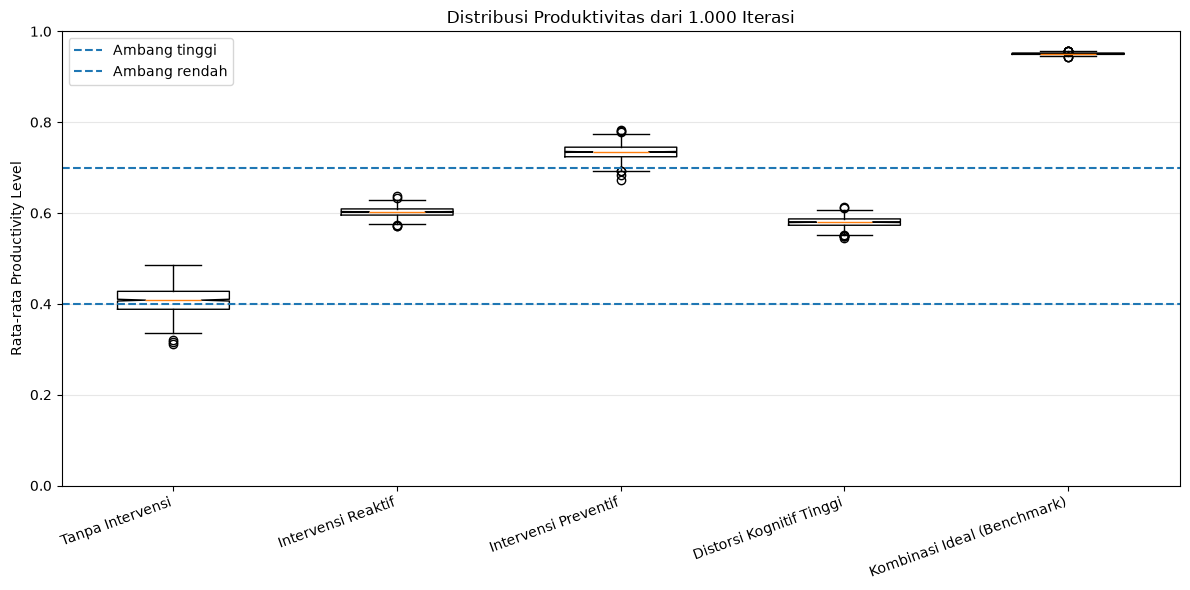

In [14]:

# Grafik 4 — Box plot distribusi Avg_PL dari 1.000 iterasi
data_box = [
    df_iterasi.loc[df_iterasi["Skenario"] == nama, "Avg_PL"].values
    for nama in urutan
]

plt.figure(figsize=(12, 6))
plt.boxplot(
    data_box,
    tick_labels=urutan,
    notch=True
)
plt.axhline(PRODUKTIVITAS_TINGGI, linestyle="--", label="Ambang tinggi")
plt.axhline(PRODUKTIVITAS_RENDAH, linestyle="--", label="Ambang rendah")
plt.ylabel("Rata-rata Productivity Level")
plt.title("Distribusi Produktivitas dari 1.000 Iterasi")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_boxplot_skenario_tidur.png", dpi=150, bbox_inches="tight")
plt.show()


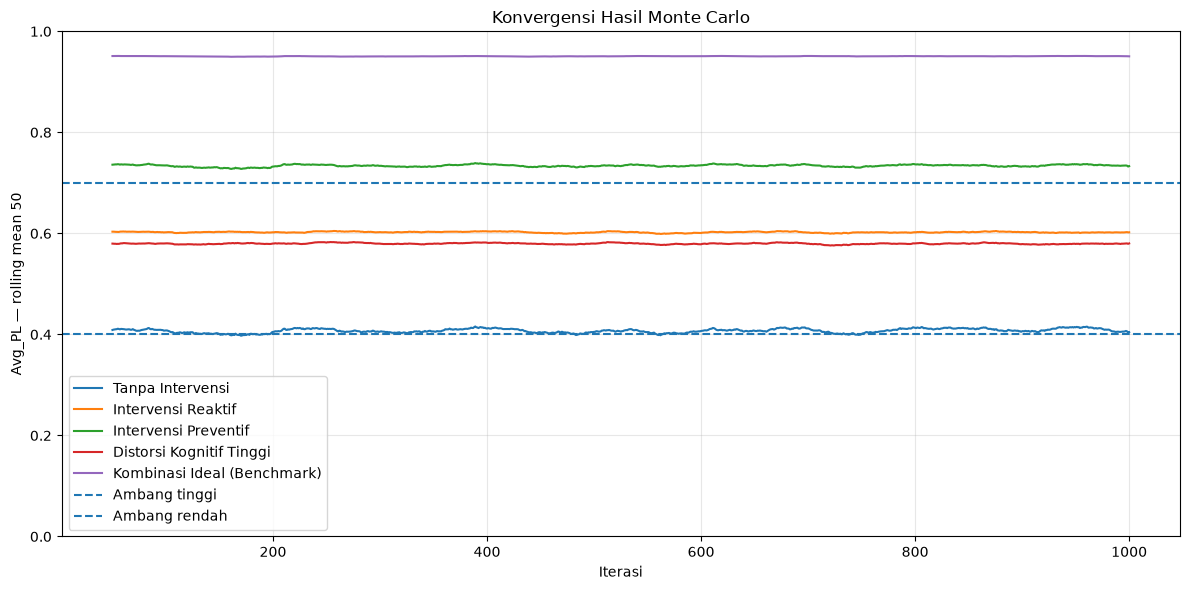

In [15]:

# Grafik 5 — Konvergensi rolling mean 50 iterasi
plt.figure(figsize=(12, 6))

for nama in urutan:
    subset = df_iterasi[df_iterasi["Skenario"] == nama].copy()
    rolling = subset["Avg_PL"].rolling(window=50).mean()
    plt.plot(subset["Iterasi"], rolling, label=nama)

plt.axhline(PRODUKTIVITAS_TINGGI, linestyle="--", label="Ambang tinggi")
plt.axhline(PRODUKTIVITAS_RENDAH, linestyle="--", label="Ambang rendah")
plt.xlabel("Iterasi")
plt.ylabel("Avg_PL — rolling mean 50")
plt.title("Konvergensi Hasil Monte Carlo")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("grafik_konvergensi_tidur.png", dpi=150, bbox_inches="tight")
plt.show()


## 13. Interpretasi Otomatis

In [16]:

best = df_results.loc[df_results["Avg_PL"].idxmax()]
worst = df_results.loc[df_results["Avg_PL"].idxmin()]

# Efisiensi intervensi dihitung sebagai tambahan Avg_PL dibandingkan
# skenario tanpa intervensi, dibagi frekuensi intervensi.
baseline_pl = float(
    df_results.loc[
        df_results["Skenario"].astype(str) == "Tanpa Intervensi",
        "Avg_PL"
    ].iloc[0]
)

df_results["Gain_vs_Tanpa_Intervensi"] = (
    df_results["Avg_PL"] - baseline_pl
)

df_results["Gain_PL_per_Intervensi"] = np.where(
    df_results["Avg_Intervensi"] > 0,
    df_results["Gain_vs_Tanpa_Intervensi"] / df_results["Avg_Intervensi"],
    np.nan
)

kandidat_efisiensi = df_results[
    (df_results["Kategori"] == "Eksperimen utama")
    & (df_results["Avg_Intervensi"] > 0)
].copy()

efisien = kandidat_efisiensi.loc[
    kandidat_efisiensi["Gain_PL_per_Intervensi"].idxmax()
]

print("=" * 80)
print("RINGKASAN HASIL")
print("=" * 80)
print(f"Skenario dengan Avg_PL tertinggi     : {best['Skenario']}")
print(f"Skenario dengan Avg_PL terendah      : {worst['Skenario']}")
print(f"Efisiensi intervensi utama tertinggi : {efisien['Skenario']}")
print()

for _, row in df_results.iterrows():
    print(
        f"{str(row['Skenario']):<32} | "
        f"PL={row['Avg_PL']:.4f} | "
        f"CI95=[{row['CI95_Bawah']:.4f}, {row['CI95_Atas']:.4f}] | "
        f"Rendah={row['Pct_Produktivitas_Rendah']:.2f}% | "
        f"Intervensi={row['Avg_Intervensi']:.2f}"
    )

print("=" * 80)
print(
    "Efisiensi di atas membandingkan kenaikan PL terhadap skenario tanpa "
    "intervensi per satu kali intervensi. Kombinasi Ideal tidak dimasukkan "
    "dalam perbandingan efisiensi karena merupakan benchmark dengan beberapa "
    "kondisi awal yang berbeda."
)


RINGKASAN HASIL
Skenario dengan Avg_PL tertinggi     : Kombinasi Ideal (Benchmark)
Skenario dengan Avg_PL terendah      : Tanpa Intervensi
Efisiensi intervensi utama tertinggi : Intervensi Reaktif

Tanpa Intervensi                 | PL=0.4073 | CI95=[0.4056, 0.4090] | Rendah=53.02% | Intervensi=0.00
Intervensi Reaktif               | PL=0.6024 | CI95=[0.6018, 0.6030] | Rendah=0.03% | Intervensi=6.66
Intervensi Preventif             | PL=0.7340 | CI95=[0.7331, 0.7350] | Rendah=0.03% | Intervensi=16.00
Distorsi Kognitif Tinggi         | PL=0.5798 | CI95=[0.5792, 0.5805] | Rendah=0.66% | Intervensi=9.41
Kombinasi Ideal (Benchmark)      | PL=0.9507 | CI95=[0.9505, 0.9508] | Rendah=0.00% | Intervensi=16.00
Efisiensi di atas membandingkan kenaikan PL terhadap skenario tanpa intervensi per satu kali intervensi. Kombinasi Ideal tidak dimasukkan dalam perbandingan efisiensi karena merupakan benchmark dengan beberapa kondisi awal yang berbeda.


## 14. Ekspor Data untuk Dashboard

In [17]:

# Semua file disimpan pada direktori kerja aktif.
output_files = {
    "dataset_dummy_awal.csv": df_dummy_presentasi,
    "hasil_longitudinal_demo.csv": df_demo,
    "hasil_iterasi_simulasi_tidur.csv": df_iterasi,
    "ringkasan_skenario_simulasi_tidur.csv": df_results,
    "parameter_skenario_simulasi_tidur.csv": df_parameter_skenario,
}

for filename, dataframe in output_files.items():
    dataframe.to_csv(filename, index=False)

print("File data yang dihasilkan:")
for filename in output_files:
    print(f"- {filename}")

print("\nFile grafik yang dihasilkan:")
for filename in [
    "grafik_demo_lima_agen.png",
    "grafik_rata_rata_pl_ci95.png",
    "grafik_state_akhir.png",
    "grafik_frekuensi_intervensi.png",
    "grafik_boxplot_skenario_tidur.png",
    "grafik_konvergensi_tidur.png",
]:
    print(f"- {filename}")


File data yang dihasilkan:
- dataset_dummy_awal.csv
- hasil_longitudinal_demo.csv
- hasil_iterasi_simulasi_tidur.csv
- ringkasan_skenario_simulasi_tidur.csv
- parameter_skenario_simulasi_tidur.csv

File grafik yang dihasilkan:
- grafik_demo_lima_agen.png
- grafik_rata_rata_pl_ci95.png
- grafik_state_akhir.png
- grafik_frekuensi_intervensi.png
- grafik_boxplot_skenario_tidur.png
- grafik_konvergensi_tidur.png



## 15. Hubungan Notebook dengan Dashboard

Dashboard dapat membaca file berikut:

- `ringkasan_skenario_simulasi_tidur.csv` untuk kartu indikator dan tabel perbandingan;
- `hasil_iterasi_simulasi_tidur.csv` untuk box plot dan distribusi;
- `hasil_longitudinal_demo.csv` untuk grafik perubahan mingguan;
- `parameter_skenario_simulasi_tidur.csv` untuk menampilkan konfigurasi skenario;
- `dataset_dummy_awal.csv` untuk menjelaskan proses pembentukan data.

### Komponen dashboard yang disarankan
1. Pilihan skenario.
2. Slider jumlah mahasiswa dan lama simulasi.
3. Slider `SH`, `SQ`, `SR`, `AS`, `D`, dan `HI`.
4. Grafik produktivitas per minggu.
5. Kartu rata-rata PL, persentase rendah, SleepScore, dan frekuensi intervensi.
6. Tabel hasil simulasi.
7. Tombol unduh CSV.

Notebook ini difokuskan pada validasi model dan pembentukan output. Implementasi Streamlit dapat dibuat sebagai tahap terpisah.



## 16. Keterbatasan dan Kesimpulan

### Keterbatasan
- Parameter bobot belum dikalibrasi menggunakan data survei nyata.
- Tidak ada interaksi sosial langsung antaragen.
- Stressor lingkungan baru direpresentasikan oleh tekanan akademik dan minggu ujian.
- Intervensi higiene tidur disederhanakan menjadi perubahan numerik.
- Productivity Level merupakan indeks simulasi, bukan nilai akademik riil atau diagnosis medis.

### Kesimpulan metodologis
- Dataset dummy dibuat secara eksplisit dan dapat direproduksi.
- Model telah menggunakan struktur Agent-Based Modeling dari Mesa.
- Tiga skenario utama menggunakan kondisi awal yang sama.
- Distorsi kognitif tinggi diuji dengan mengubah parameter `D` saja.
- Hasil diperoleh dari 1.000 iterasi per skenario dan dilengkapi CI 95%.
- Output telah disiapkan dalam format CSV dan PNG untuk dashboard.

### Urutan penjelasan presentasi
1. Latar belakang dan tujuan.
2. Definisi agen, lingkungan, stressor, dan intervensi.
3. Data dictionary.
4. Pembuatan dataset dummy.
5. Formula matematika.
6. State chart.
7. Kelas `Mahasiswa`.
8. Kelas model Mesa.
9. Demo lima agen.
10. Definisi skenario.
11. Monte Carlo 1.000 iterasi.
12. Tabel dan grafik hasil.
13. Interpretasi dan keterbatasan.
14. Hubungan output dengan dashboard.
